## Ćwiczenie 11: Przekształcenia geometryczne obrazów

Zanim zautomatyzujemy proces dopasowywania obrazów (rejestrację), musimy zrozumieć mechanikę ich przekształcania przestrzennego. W tym notatniku poznamy:
1. **Macierze transformacji (Affine Transform):** Jak matematycznie przesunąć (translacja) i obrócić (rotacja) obraz.
2. **Odwrotne mapowanie (Inverse Mapping):** Dlaczego przekształcamy obrazy "od tyłu" (żeby uniknąć pustych pikseli).
3. **Interpolację:** Jak wyliczyć wartość piksela, gdy ze wzoru geometrycznego wychodzą współrzędne ułamkowe (np. `x=12.4`, `y=15.8`).

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, transform
import math

### 1. Transformacje Afiniczne (Translacja i Rotacja)
Biblioteka `scikit-image` używa klasy `AffineTransform` do definiowania przekształceń oraz funkcji `warp` do aplikowania ich na obraz.

**Ważne (problem pustych pikseli):** Funkcja `warp` domyślnie oczekuje transformacji **odwrotnej** (`inverse`). 

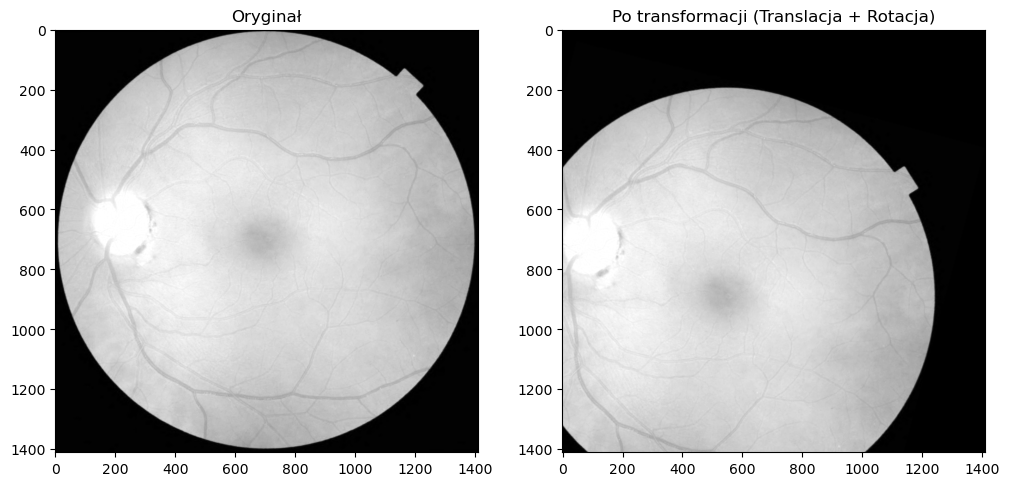

In [16]:
# Wczytanie obrazu medycznego (siatkówka oka)
try:
    image = data.retina()[..., 0] # Pobieramy tylko jeden kanał (grayscale)
except AttributeError:
    image = data.camera() # Awaryjnie, jeśli brakuje modułu retina

image = image / image.max()

# Definicja przekształcenia: Przesunięcie o (X=50, Y=30) i obrót o 15 stopni
kat_stopnie = 15
tform = transform.AffineTransform(translation=(50, 30), rotation=math.radians(kat_stopnie))

# Aplikacja przekształcenia (Zwróć uwagę na podanie tform.inverse!)
warped_image = transform.warp(image, tform.inverse)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(image, cmap='gray')
ax[0].set_title('Oryginał')
ax[1].imshow(warped_image, cmap='gray')
ax[1].set_title('Po transformacji (Translacja + Rotacja)')
plt.show()

### 2. Rola Interpolacji (kluczowe w obrazowaniu medycznym!)

Kiedy obracamy lub skalujemy obraz, nowe współrzędne niezwykle rzadko są liczbami całkowitymi. Algorytm musi "zgadnąć", jaką jasność ma mieć piksel na ułamkowej pozycji (np. w połowie drogi między dwoma prawdziwymi pikselami).

Parametr `order` w funkcji `warp` decyduje o sposobie interpolacji:
* **`order=0` (Najbliższy sąsiad / Nearest Neighbor):** Przypisuje wartość fizycznie najbliższego piksela. Zachowuje oryginalne wartości i ostre krawędzie, doskonałe do przekształcania **binarnych masek segmentacji**, ale linie stają się "schodkowane".
* **`order=1` (Dwuliniowa / Bilinear):** Uśrednia 4 najbliższych sąsiadów. Obraz jest dużo gładszy, ale algorytm *tworzy nowe wartości* (pośrednie odcienie szarości), których fizycznie nie było na oryginalnym skanie.

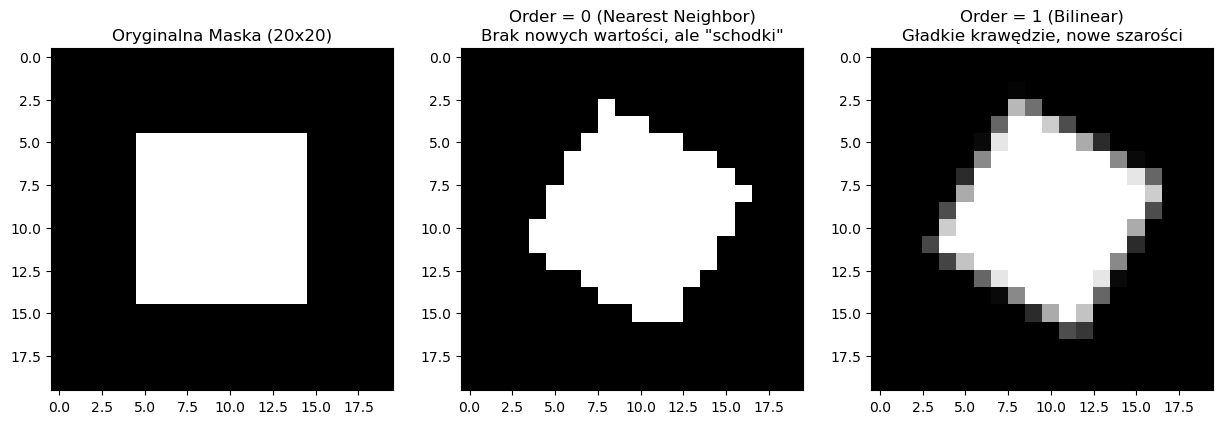

In [19]:
# Stwórzmy mały obraz (imitujący twardą binarną maskę), żeby zobaczyć pojedyncze piksele
small_img = np.zeros((20, 20))
small_img[5:15, 5:15] = 1.0

# Obrót o 30 stopni wokół środka obrazka (współrzędne 10, 10)
# Aby obrócić wokół punktu, musimy najpierw przesunąć punkt (0,0) na środek, obrócić i wrócić
shift_y, shift_x = 10, 10
tform_center = transform.AffineTransform(translation=(-shift_x, -shift_y)) \
               + transform.AffineTransform(rotation=math.radians(30)) \
               + transform.AffineTransform(translation=(shift_x, shift_y))

# Interpolacja rzędu 0 (Nearest Neighbor)
warp_order0 = transform.warp(small_img, tform_center.inverse, order=0)

# Interpolacja rzędu 1 (Bilinear)
warp_order1 = transform.warp(small_img, tform_center.inverse, order=1)

# Wizualizacja różnic (zwróć uwagę na schodki w order=0 i rozmyte szarości w order=1)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(small_img, cmap='gray')
ax[0].set_title('Oryginalna Maska (20x20)')

ax[1].imshow(warp_order0, cmap='gray')
ax[1].set_title('Order = 0 (Nearest Neighbor)\nBrak nowych wartości, ale "schodki"')

ax[2].imshow(warp_order1, cmap='gray')
ax[2].set_title('Order = 1 (Bilinear)\nGładkie krawędzie, nowe szarości')
plt.show()